In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load training data
data_train = pd.read_csv("/content/drive/MyDrive/Polynomialdata_train.csv")
print(data_train)


             target  feature 1  feature 2  feature 3
0      4.131528e+06   5.221849   7.295111  95.716846
1      3.172975e-01  -5.106284   4.220085  -6.172360
2      4.676422e+04  -4.218053  -7.573823 -39.493884
3      1.404175e+05 -18.439122  -2.275148 -40.885857
4      4.788988e+03  13.353046   3.103837  18.622367
...             ...        ...        ...        ...
49995  1.853922e+04 -25.309264  -6.094516  75.361431
49996  6.379917e+03 -58.016982  -6.064214  27.146387
49997  3.835601e+06  29.857894   1.422973  75.620505
49998  2.580318e+04  10.793146   1.215972  34.437761
49999  3.468171e+05  12.171702  -0.798756  60.245990

[50000 rows x 4 columns]


In [ ]:
data_train.describe()

,target,feature 1,feature 2,feature 3
count,5.000000e+04,50000.000000,50000.000000,50000.000000
mean,1.773548e+06,0.099964,0.012562,-0.205100
std,1.139467e+07,21.842028,4.000527,56.045907
min,-5.353391e+02,-102.142087,-17.236805,-251.346206
25%,1.366923e+02,-14.424551,-2.708389,-37.961040
50%,1.178718e+04,0.265138,0.026296,-0.278907
75%,2.812790e+05,14.773691,2.698501,37.528504
max,8.392773e+08,92.676100,17.647059,232.683184


In [ ]:
# Load test data
data_test = pd.read_csv("/content/drive/MyDrive/Polynomialdata_test.csv")
print(data_test)


         ID  feature 1  feature 2  feature 3
0     16588  36.247643  -2.372704  43.835947
1     17513   5.903779   5.460086 -96.149414
2     14448 -37.298157   6.869786 -14.084487
3     13972 -40.080077   2.395066 -43.432941
4     18321 -20.417799  -2.194459   5.737226
...     ...        ...        ...        ...
9995  19691 -13.571554   2.931176  76.902716
9996  10512  -2.015904  -2.827700   4.999604
9997  17741  47.095192  -1.977461  39.044902
9998  18381  -1.808178  -0.693782  57.918628
9999  12054  19.958034   2.294516 -16.082546

[10000 rows x 4 columns]


In [ ]:
# Convert training data to NumPy array
data_train = pd.read_csv("/content/drive/MyDrive/Polynomialdata_train.csv").to_numpy()
print(data_train)


[[ 4.13152828e+06  5.22184894e+00  7.29511056e+00  9.57168455e+01]
 [ 3.17297454e-01 -5.10628445e+00  4.22008546e+00 -6.17236000e+00]
 [ 4.67642163e+04 -4.21805344e+00 -7.57382297e+00 -3.94938840e+01]
 ...
 [ 3.83560105e+06  2.98578942e+01  1.42297302e+00  7.56205054e+01]
 [ 2.58031768e+04  1.07931457e+01  1.21597176e+00  3.44377606e+01]
 [ 3.46817108e+05  1.21717022e+01 -7.98756316e-01  6.02459898e+01]]


In [ ]:
# Convert test data to NumPy array
data_test = pd.read_csv("/content/drive/MyDrive/Polynomialdata_test.csv").to_numpy()
print(data_test)


[[ 1.65880000e+04  3.62476426e+01 -2.37270368e+00  4.38359472e+01]
 [ 1.75130000e+04  5.90377936e+00  5.46008554e+00 -9.61494142e+01]
 [ 1.44480000e+04 -3.72981567e+01  6.86978600e+00 -1.40844875e+01]
 ...
 [ 1.77410000e+04  4.70951921e+01 -1.97746088e+00  3.90449021e+01]
 [ 1.83810000e+04 -1.80817812e+00 -6.93781616e-01  5.79186278e+01]
 [ 1.20540000e+04  1.99580337e+01  2.29451622e+00 -1.60825461e+01]]


In [ ]:
# Extract features and target variable from training data
x = data_train[:, 1:]
y = data_train[:, 0].reshape((50000, 1))
w = np.ones((50000, 1))
x = np.hstack((x, w))
x


array([[  5.22184894,   7.29511056,  95.71684555,   1.        ],
       [ -5.10628445,   4.22008546,  -6.17236   ,   1.        ],
       [ -4.21805344,  -7.57382297, -39.49388399,   1.        ],
       ...,
       [ 29.85789417,   1.42297302,  75.62050543,   1.        ],
       [ 10.79314567,   1.21597176,  34.43776063,   1.        ],
       [ 12.17170222,  -0.79875632,  60.24598982,   1.        ]])

In [ ]:
# Initialize variables
m, n = x.shape
X = np.ones((m, 1))
degree = 5

# Generate polynomial features
for k in range(degree):
    for j in range(degree):
        for i in range(degree):
            a = np.power(x[:, 0], i)
            b = np.power(x[:, 1], j)
            c = np.power(x[:, 2], k)
            if (i + j + k > degree):
                continue
            else:
                d = a * b * c
                d.resize((50000, 1))
                X = np.hstack((X, d))

print(X.shape)


(50000, 54)


In [ ]:
# Polynomial regression function
def polyreg(x, y, learning_rate, iteration):
    p, q = X.shape
    theta = np.zeros((q, 1))
    costs=[]
    for i in range(iteration):
        y_pred = np.matmul(X, theta)
        cost = 1 / (2 * m) * np.sum(np.square(y_pred - y))
        dtheta = (1 / m) * np.matmul(X.T, (y_pred - y))
        theta = theta - learning_rate * dtheta


        if i % 5000 == 0:
            print("iteration:", i, " cost:", cost)
            costs.append(cost)

    return theta, costs, y_pred

# Set hyperparameters
iteration = 50000
learning_rate = 0.0000000000000000003

# Perform polynomial regression
theta, costs, y_pred = polyreg(X, y, learning_rate=learning_rate, iteration=iteration)
print(theta)


iteration: 0  cost: 66490664333888.97
iteration: 5000  cost: 19485549363234.61
iteration: 10000  cost: 15739885956233.814
iteration: 15000  cost: 13764887566112.062
iteration: 20000  cost: 12713794530773.016
iteration: 25000  cost: 12145515087590.846
iteration: 30000  cost: 11830048563191.484
iteration: 35000  cost: 11647359699395.938
iteration: 40000  cost: 11534749598314.146
iteration: 45000  cost: 11459436588704.521
[[-1.27661681e-08]
 [-1.27661681e-08]
 [ 1.56477634e-08]
 [ 2.56218781e-06]
 [-5.49651885e-05]
 [ 1.65976728e-02]
 [-4.91521762e-09]
 [ 3.52879202e-07]
 [-3.78516293e-06]
 [ 7.25914394e-04]
 [-1.13300945e-02]
 [-1.97202239e-07]
 [ 5.79322880e-07]
 [ 5.66093947e-05]
 [-3.15100454e-04]
 [-2.38416952e-07]
 [ 1.70823839e-05]
 [-1.89579381e-04]
 [-9.63500955e-06]
 [ 6.02624681e-05]
 [ 1.43448128e-07]
 [ 8.86074101e-06]
 [ 1.22787657e-04]
 [ 2.13547783e-02]
 [ 2.90830694e-03]
 [ 2.20428848e-06]
 [-1.32920015e-05]
 [ 1.65966309e-03]
 [-1.31501752e-02]
 [ 3.39434331e-06]
 [ 1.48

In [ ]:
theta.shape

(54, 1)

In [ ]:
E1 = np.sum((y-y_pred)**2)
mean = np.mean(y)
E2 = np.sum((y - mean)**2)

r2_score = 1-(E1/E2)**2
r2_score


0.9691393135468336

In [ ]:
# Load the test data
data_test = pd.read_csv("/content/drive/MyDrive/Polynomialdata_test.csv").to_numpy()

# Extract features and add bias term
x_test = data_test[:, 1:]
x_test = np.hstack((x_test, np.ones((len(x_test), 1))))

# Generate polynomial features for the test data
X_test = np.ones((len(x_test), 1))

for k in range(degree):
    for j in range(degree):
        for i in range(degree):
            a = np.power(x_test[:, 0], i)
            b = np.power(x_test[:, 1], j)
            c = np.power(x_test[:, 2], k)
            if (i + j + k > degree):
                continue
            else:
                d = a * b * c
                d.resize((len(x_test), 1))
                X_test = np.hstack((X_test, d))

# Make predictions on the test data
y_pred_test = X_test.dot(theta)

# Print or use y_pred_test as needed
print("Predictions on the test data:")
print(y_pred_test)


Predictions on the test data:
[[1231593.85437021]
 [6039880.61996385]
 [ -83198.23878094]
 ...
 [1574951.17173166]
 [ 920538.16289991]
 [ -12136.08870548]]


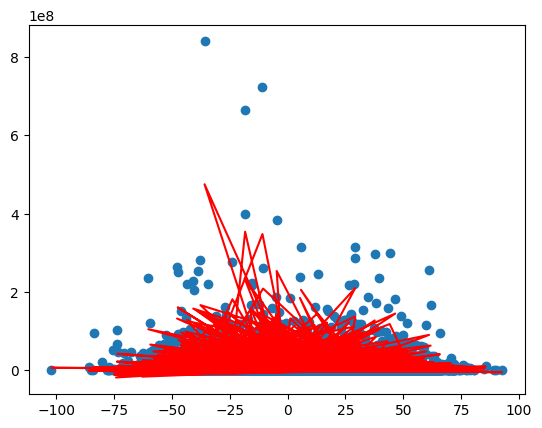

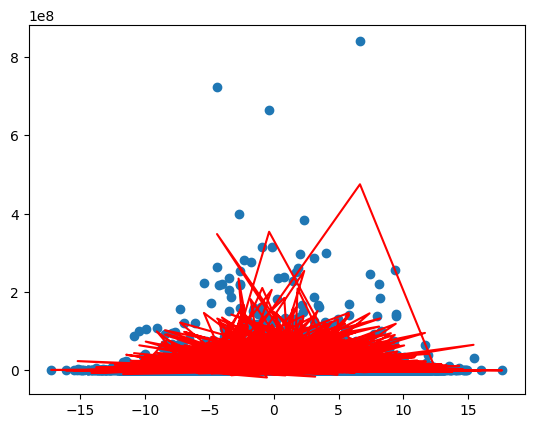

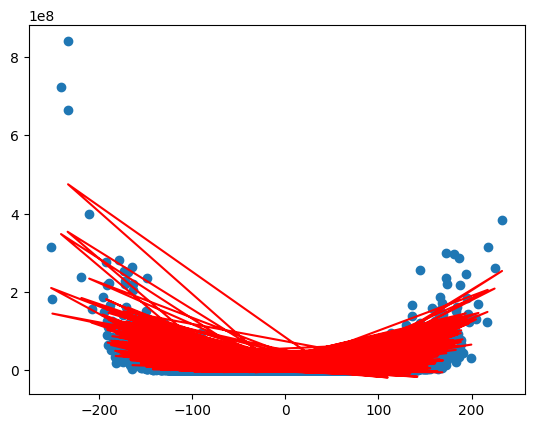

In [ ]:
plt.scatter(x[:,0],y)
plt.plot(x[:,0],y_pred,color = 'red')
plt.show()
plt.scatter(x[:,1],y)
plt.plot(x[:,1],y_pred,color = 'red')
plt.show()
plt.scatter(x[:,2],y)
plt.plot(x[:,2],y_pred,color = 'red')
plt.show()

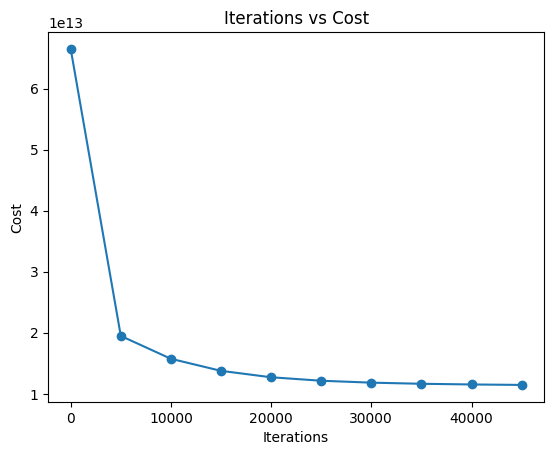

In [ ]:
iterations = np.arange(0, iteration + 1, int(iteration / len(costs)))
plt.plot(iterations[:len(costs)], costs, marker='o')
plt.title('Iterations vs Cost')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.show()